# Task 1 – Load and Plot Raw Temperature Data

   _id        Date Rain     Temp Max     Temp Min
0    1  01-01-1951    0  20.13999939  3.680000067
1    2  02-01-1951    0  21.68000031  3.599999905
2    3  03-01-1951    0  21.28000069   3.50999999
3    4  04-01-1951    0  21.61000061  4.090000153
4    5  05-01-1951    0  21.38999939  5.099999905

Columns:
Index(['_id', 'Date', 'Rain', 'Temp Max', 'Temp Min'], dtype='object')

Prepared Dataset:
            Temperature
Date                   
1951-01-01    11.910000
1951-01-02    15.185000
1951-01-03    21.820000
1951-01-04    21.405000
1951-01-05    32.254999


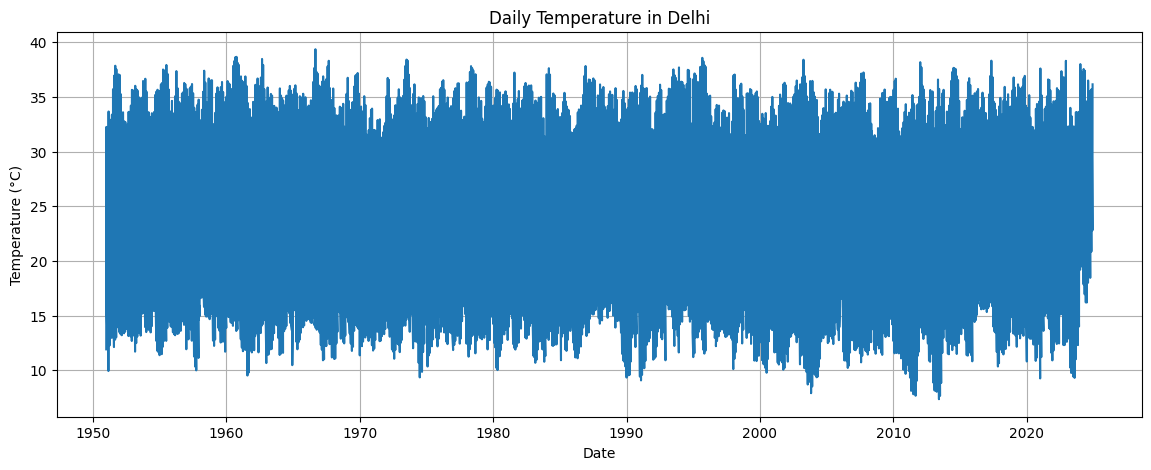

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("delhi_temperature.csv")

# Display dataset
print(df.head())
print("\nColumns:")
print(df.columns)

# Convert date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert temperature columns to numeric
df["Temp Max"] = pd.to_numeric(df["Temp Max"], errors="coerce")
df["Temp Min"] = pd.to_numeric(df["Temp Min"], errors="coerce")

# Calculate average temperature
df["Temperature"] = (df["Temp Max"] + df["Temp Min"]) / 2

# Remove missing values
df = df.dropna(subset=["Date", "Temperature"])

# Sort by date
df = df.sort_values("Date")

# Set date as index
df = df.set_index("Date")

# Remove duplicate dates and average if necessary
df = df.groupby(level=0)["Temperature"].mean().to_frame()

print("\nPrepared Dataset:")
print(df.head())

# Plot raw temperature
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Temperature"])

plt.title("Daily Temperature in Delhi")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid()
plt.show()

# Task 2 – Seasonal Decomposition

C:\Users\admin\AppData\Local\Temp\ipykernel_8152\4021568129.py:8: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  temperature_recent = temperature.last("5YE")


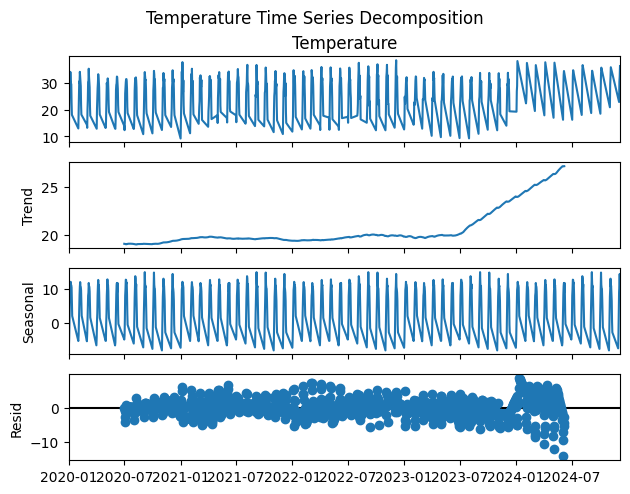

In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Convert data into daily frequency and fill missing dates
temperature = df["Temperature"].asfreq("D")
temperature = temperature.interpolate(method="time")

# Use the most recent 5 years
temperature_recent = temperature.last("5YE")

# Decompose temperature data
decomposition = seasonal_decompose(
    temperature_recent,
    model="additive",
    period=365
)

# Plot components
decomposition.plot()

plt.suptitle("Temperature Time Series Decomposition", y=1.02)
plt.show()

# Task 3 – Check Stationarity using ADF Test

In [3]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test
adf_result = adfuller(temperature.dropna())

print("ADF Test Statistic:", adf_result[0])
print("P-value:", adf_result[1])

# Check stationarity
if adf_result[1] < 0.05:
    print("\nThe temperature series is Stationary.")
else:
    print("\nThe temperature series is Non-Stationary.")

ADF Test Statistic: -5.925854656575963
P-value: 2.444775134442221e-07

The temperature series is Stationary.


# Task 4 – Moving Average Smoothing

C:\Users\admin\AppData\Local\Temp\ipykernel_8152\843094980.py:8: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  temperature.last("1YE"),
C:\Users\admin\AppData\Local\Temp\ipykernel_8152\843094980.py:14: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  moving_average.last("1YE"),


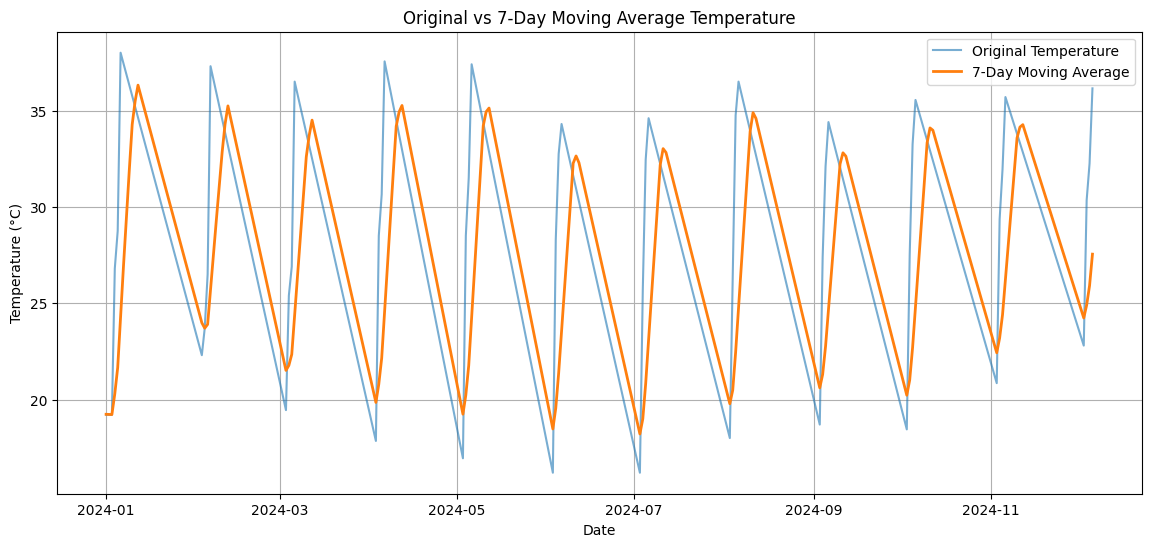

In [4]:
# Calculate 7-day moving average
moving_average = temperature.rolling(window=7).mean()

# Plot original and smoothed data
plt.figure(figsize=(14, 6))

plt.plot(
    temperature.last("1YE"),
    label="Original Temperature",
    alpha=0.6
)

plt.plot(
    moving_average.last("1YE"),
    label="7-Day Moving Average",
    linewidth=2
)

plt.title("Original vs 7-Day Moving Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid()
plt.show()

# Task 5 – ARIMA Model and 7-Day Forecast

In [5]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# Use recent 3 years for faster model training
train_data = temperature.last("3YE").dropna()

# Check stationarity
p_value = adfuller(train_data)[1]

# Select differencing value
if p_value < 0.05:
    d = 0
else:
    d = 1

# Select ARIMA parameters
p = 1
q = 1

print("Selected ARIMA Order:", (p, d, q))

# Train ARIMA model
model = ARIMA(train_data, order=(p, d, q))
model_fit = model.fit()

# Forecast next 7 days
forecast = model_fit.forecast(steps=7)

# Display predicted values
forecast_dates = pd.date_range(
    start=train_data.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": forecast_dates,
    "Predicted Temperature": forecast.values
})

print("\nNext 7 Days Temperature Forecast:")
print(forecast_df)

C:\Users\admin\AppData\Local\Temp\ipykernel_8152\341395742.py:5: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  train_data = temperature.last("3YE").dropna()


Selected ARIMA Order: (1, 0, 1)

Next 7 Days Temperature Forecast:
        Date  Predicted Temperature
0 2024-12-07              35.911896
1 2024-12-08              34.580026
2 2024-12-09              33.379011
3 2024-12-10              32.295997
4 2024-12-11              31.319390
5 2024-12-12              30.438734
6 2024-12-13              29.644603


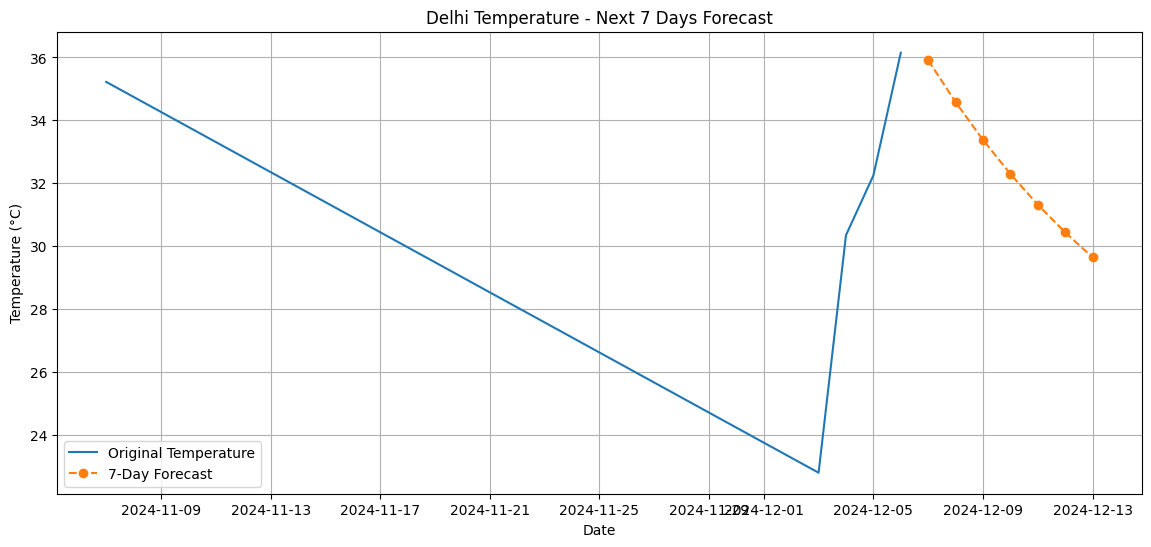

In [6]:
# Plot original data and forecast
plt.figure(figsize=(14, 6))

# Show last 30 days of original data
plt.plot(
    train_data.tail(30),
    label="Original Temperature"
)

# Plot forecast
plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted Temperature"],
    marker="o",
    linestyle="--",
    label="7-Day Forecast"
)

plt.title("Delhi Temperature - Next 7 Days Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid()
plt.show()